# SEMMA — Predicting Heart Disease (UCI Cleveland Dataset)

**Course:** CMPE 256 — Data Mining | **Methodology:** SEMMA (Sample, Explore, Modify, Model, Assess)
**Dataset:** UCI Heart Disease, Cleveland processed set — 303 rows × 14 attributes
**Author:** Pranith Varma Pakalapati (SJSU)

> ⚠️ **CLINICAL DISCLAIMER — READ FIRST:** This notebook is a **teaching demonstration of the SEMMA methodology**. It is **NOT a diagnostic tool** and must never be used to diagnose, triage, or make treatment decisions for any person. The data are from a single clinic in the 1980s, the sample is small (303 patients), and the models are simple classroom baselines. Any real clinical use would require regulatory approval, far larger and more recent multi-site data, and clinician oversight.

## What is SEMMA?

SEMMA is the data-mining methodology developed for **SAS Enterprise Miner** — **S**ample, **E**xplore, **M**odify, **M**odel, **A**ssess. Unlike CRISP-DM, which starts with business understanding and ends with deployment planning, SEMMA is a tighter, model-centric workflow: it assumes the problem is already defined and focuses on getting from raw data to an assessed model. Each phase below maps to a SAS Enterprise Miner node; because no SAS licence was available for this assignment, every step is implemented in **Python (scikit-learn)** with its SAS-equivalent node named explicitly. The logic — not the vendor tool — is what is being demonstrated.

| SEMMA phase | SAS Enterprise Miner node(s) | Python equivalent used here |
|---|---|---|
| Sample | Data Partition | `train_test_split` (stratified), `StratifiedKFold` |
| Explore | StatExplore, Graph Explore, MultiPlot | pandas describe, seaborn/matplotlib |
| Modify | Impute, Transform Variables, Variable Selection, Replacement | `SimpleImputer`, `OneHotEncoder`, `StandardScaler` |
| Model | Regression, Decision Tree, Neural Network, Gradient Boosting | Logistic Regression, Random Forest, HistGradientBoosting |
| Assess | Model Comparison, ROC, Lift, Score | ROC-AUC, confusion matrix, calibration, subgroup checks |

**Target definition:** the raw `target` column is 0 = no disease, 1–4 = disease of increasing severity. For this binary classification task it is **binarized to 0/1** (0 = no disease, 1 = disease present). This is stated explicitly because it changes the problem from 5-class to binary classification.


In [1]:
# Cell 1 — Install dependencies (Colab: run this first; harmless if already installed)
# %pip installs into the kernel's own environment, so this works in Colab and locally.
%pip install -q pandas numpy scikit-learn matplotlib seaborn
print("Dependencies ready.")


Note: you may need to restart the kernel to use updated packages.
Dependencies ready.


In [2]:
# Cell 2 — Download the dataset (UCI Machine Learning Repository)
import os, urllib.request

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
DATA_PATH = "data/processed.cleveland.data"

os.makedirs("data", exist_ok=True)
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    print("Downloaded:", DATA_URL)
else:
    print("Using existing local file:", DATA_PATH)

print("File size (bytes):", os.path.getsize(DATA_PATH))


Using existing local file: data/processed.cleveland.data
File size (bytes): 18461


In [3]:
# Cell 3 — Imports and global settings
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
# Compatibility shim (local venv only; harmless no-op in Colab): this venv pairs
# system matplotlib 3.6.3 with IPython 9, which removed `backend2gui` from
# IPython.core.pylabtools. Without this stub, pyplot's REPL display hook fails
# on first use. Colab's IPython still ships backend2gui, so the hasattr check
# skips the patch there.
import IPython.core.pylabtools as _pylabtools
if not hasattr(_pylabtools, "backend2gui"):
    import types as _types
    _pylabtools.backend2gui = _types.SimpleNamespace(get=lambda backend: None)
import matplotlib
matplotlib.use("Agg")  # headless-safe backend; charts are shown from the saved PNGs below
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, classification_report)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]
print("Seed fixed at 42 everywhere. Libraries loaded.")


Seed fixed at 42 everywhere. Libraries loaded.


---

## Phase 1 — SAMPLE

**SAS node:** Data Partition.

**Sampling strategy.** The full Cleveland set has only **303 rows**. Down-sampling a dataset this small would throw away information we cannot afford to lose, so **no down-sampling is performed** — the whole dataset is used, and the "sample" step is instead a careful, reproducible *partition*:

- **Stratified 80/20 train/test split** (seed 42) — stratification preserves the 45.9% disease prevalence in both parts.
- **5-fold stratified cross-validation** on the training set for model comparison, so model choice is not decided by one lucky split.

**Sampling bias — read this before trusting any result:**
- **Single site:** all patients come from the Cleveland Clinic (1980s). Practice patterns, referral mix, and measurement equipment are those of one hospital, one era.
- **Male-heavy:** 206 men vs 97 women (68% male); disease prevalence is 55.3% in men vs 25.8% in women, so the model mostly learns male presentations.
- **Referral bias:** patients were referred for cardiac evaluation, so they are sicker than the general population — prevalence here (45.9%) is far above the general population.
- **Era:** diagnostic thresholds and treatments have changed since the 1980s; a model trained on this data would not be expected to generalise to a modern, multi-site, diverse population without re-validation.

**Generalizability limit:** results describe *this* cohort only. Any deployment claim would require external validation on a different hospital and a different decade.


In [4]:
# Phase 1 — SAMPLE: load and partition
df = pd.read_csv(DATA_PATH, header=None, names=COLUMNS)

print("Shape:", df.shape, " (rows, columns)")
print("\nColumn dtypes:")
print(df.dtypes)
print("\nRaw target distribution (0 = no disease, 1-4 = disease severity):")
print(df["target"].value_counts().sort_index())

# Binarize target: 0 = no disease, 1-4 = disease present
df["target_bin"] = (df["target"] > 0).astype(int)
print("\nBinarized target: 0 =", (df["target_bin"] == 0).sum(),
      "| 1 =", (df["target_bin"] == 1).sum(),
      "| prevalence =", round(df["target_bin"].mean(), 4))

X = df.drop(columns=["target", "target_bin"])
y = df["target_bin"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("\nTrain:", X_train.shape, "| disease rate:", round(y_train.mean(), 3))
print("Test :", X_test.shape, "| disease rate:", round(y_test.mean(), 3))
print("5-fold stratified CV will be used for model comparison (seed 42).")


Shape: (303, 14)  (rows, columns)

Column dtypes:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca           object
thal         object
target        int64
dtype: object

Raw target distribution (0 = no disease, 1-4 = disease severity):
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Binarized target: 0 = 164 | 1 = 139 | prevalence = 0.4587

Train: (242, 13) | disease rate: 0.459
Test : (61, 13) | disease rate: 0.459
5-fold stratified CV will be used for model comparison (seed 42).


---

## Phase 2 — EXPLORE

**SAS nodes:** StatExplore, Graph Explore, MultiPlot.

Questions for this phase: what do the distributions look like? Where is data missing? Are there outliers? Which variables move with the target?


In [5]:
# Phase 2 — EXPLORE: univariate summaries and missingness
print("Numeric summary:")
print(df[["age", "trestbps", "chol", "thalach", "oldpeak"]].describe().round(2))

print("\nMissing values coded as '?' (per column):")
for c in COLUMNS:
    n_missing = (df[c].astype(str) == "?").sum()
    if n_missing:
        print(f"  {c}: {n_missing} missing ({n_missing / len(df):.1%})")
print("  (all other columns: 0 missing)")

print("\nCategorical value counts:")
for c in ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]:
    print(f"  {c}: {dict(df[c].astype(str).value_counts().sort_index())}")


Numeric summary:


          age  trestbps    chol  thalach  oldpeak
count  303.00    303.00  303.00   303.00   303.00
mean    54.44    131.69  246.69   149.61     1.04
std      9.04     17.60   51.78    22.88     1.16
min     29.00     94.00  126.00    71.00     0.00
25%     48.00    120.00  211.00   133.50     0.00
50%     56.00    130.00  241.00   153.00     0.80
75%     61.00    140.00  275.00   166.00     1.60
max     77.00    200.00  564.00   202.00     6.20

Missing values coded as '?' (per column):
  ca: 4 missing (1.3%)
  thal: 2 missing (0.7%)
  (all other columns: 0 missing)

Categorical value counts:
  sex: {'0.0': 97, '1.0': 206}
  cp: {'1.0': 23, '2.0': 50, '3.0': 86, '4.0': 144}
  fbs: {'0.0': 258, '1.0': 45}
  restecg: {'0.0': 151, '1.0': 4, '2.0': 148}
  exang: {'0.0': 204, '1.0': 99}
  slope: {'1.0': 142, '2.0': 140, '3.0': 21}
  ca: {'0.0': 176, '1.0': 65, '2.0': 38, '3.0': 20, '?': 4}
  thal: {'3.0': 166, '6.0': 18, '7.0': 117, '?': 2}


In [6]:
# Phase 2 — EXPLORE: outliers (IQR rule) and correlations with the target
for c in ["chol", "trestbps", "thalach", "oldpeak", "age"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    print(f"{c}: {n_out} outliers by IQR rule (bounds {q1 - 1.5*iqr:.1f} to {q3 + 1.5*iqr:.1f})")

print("\nCorrelation with binarized target (numeric columns):")
corr = df.corr(numeric_only=True)["target_bin"].drop(["target", "target_bin"]).sort_values()
print(corr.round(3))
print("\nStrongest positive: exang, oldpeak, cp. Strongest negative: thalach (max heart rate).")
print("Note: chol correlates only +0.09 with the target — surprisingly weak for a classic risk factor,")
print("which is a reminder that correlation in one small 1980s cohort is not a causal claim.")


chol: 5 outliers by IQR rule (bounds 115.0 to 371.0)
trestbps: 9 outliers by IQR rule (bounds 90.0 to 170.0)
thalach: 1 outliers by IQR rule (bounds 84.8 to 214.8)
oldpeak: 5 outliers by IQR rule (bounds -2.4 to 4.0)
age: 0 outliers by IQR rule (bounds 28.5 to 80.5)

Correlation with binarized target (numeric columns):
thalach    -0.417
fbs         0.025
chol        0.085
trestbps    0.151
restecg     0.169
age         0.223
sex         0.277
slope       0.339
cp          0.414
oldpeak     0.425
exang       0.432
Name: target_bin, dtype: float64

Strongest positive: exang, oldpeak, cp. Strongest negative: thalach (max heart rate).
Note: chol correlates only +0.09 with the target — surprisingly weak for a classic risk factor,
which is a reminder that correlation in one small 1980s cohort is not a causal claim.


In [7]:
# Phase 2 — EXPLORE: target rate by key subgroups
print("Disease rate by sex (0=female, 1=male):")
print(df.groupby("sex")["target_bin"].agg(["count", "mean"]).round(3))
print("\nDisease rate by chest-pain type cp (1=typical angina, 2=atypical, 3=non-anginal, 4=asymptomatic):")
print(df.groupby("cp")["target_bin"].agg(["count", "mean"]).round(3))
print("\nDisease rate by exercise-induced angina exang (0=no, 1=yes):")
print(df.groupby("exang")["target_bin"].agg(["count", "mean"]).round(3))
print("\nDisease rate by thalassemia thal (3=normal, 6=fixed defect, 7=reversible defect):")
print(df.groupby("thal")["target_bin"].agg(["count", "mean"]).round(3))
print("\nDisease rate by slope of peak-exercise ST segment (1=up, 2=flat, 3=down):")
print(df.groupby("slope")["target_bin"].agg(["count", "mean"]).round(3))

df["age_group"] = pd.cut(df["age"], [28, 45, 55, 65, 78],
                         labels=["29-45", "46-55", "56-65", "66-77"])
print("\nDisease rate by age group:")
print(df.groupby("age_group", observed=True)["target_bin"].agg(["count", "mean"]).round(3))


Disease rate by sex (0=female, 1=male):
     count   mean
sex              
0.0     97  0.258
1.0    206  0.553

Disease rate by chest-pain type cp (1=typical angina, 2=atypical, 3=non-anginal, 4=asymptomatic):
     count   mean
cp               
1.0     23  0.304
2.0     50  0.180
3.0     86  0.209
4.0    144  0.729

Disease rate by exercise-induced angina exang (0=no, 1=yes):
       count   mean
exang              
0.0      204  0.309
1.0       99  0.768

Disease rate by thalassemia thal (3=normal, 6=fixed defect, 7=reversible defect):
      count   mean
thal              
3.0     166  0.223
6.0      18  0.667
7.0     117  0.761
?         2  0.500

Disease rate by slope of peak-exercise ST segment (1=up, 2=flat, 3=down):


       count   mean
slope              
1.0      142  0.254
2.0      140  0.650
3.0       21  0.571

Disease rate by age group:
           count   mean
age_group              
29-45         63  0.254
46-55         88  0.375
56-65        119  0.622
66-77         33  0.485


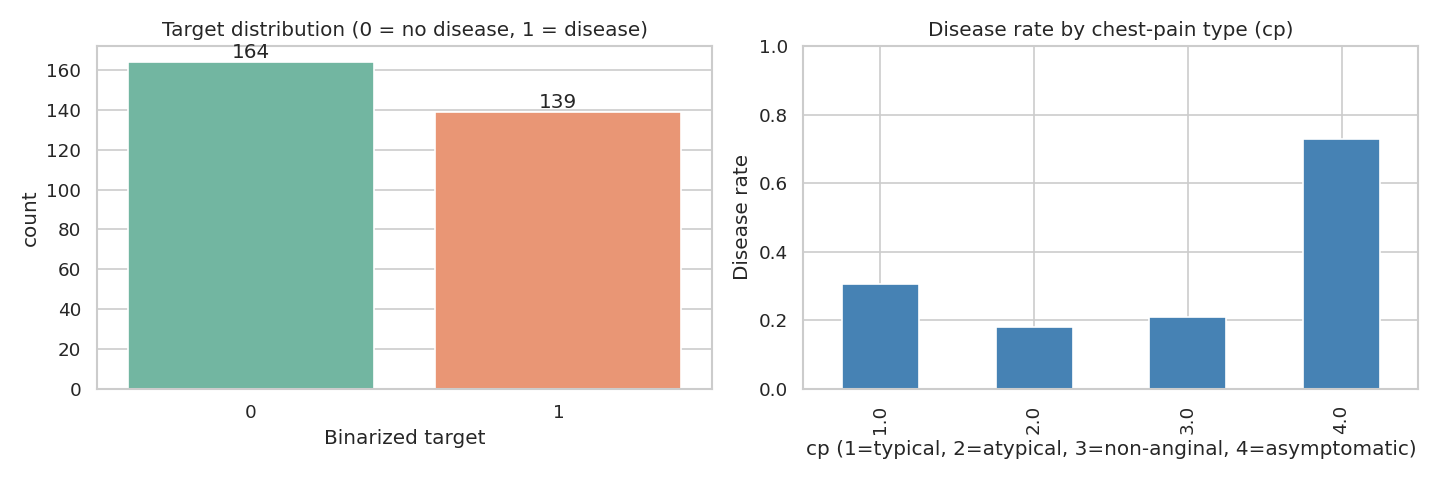

In [8]:
# Phase 2 — EXPLORE: Chart 1 — target distribution and disease rate by chest-pain type
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="target_bin", data=df, ax=axes[0], palette="Set2")
axes[0].set_title("Target distribution (0 = no disease, 1 = disease)")
axes[0].set_xlabel("Binarized target")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

cp_rate = df.groupby("cp")["target_bin"].mean()
cp_rate.plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Disease rate by chest-pain type (cp)")
axes[1].set_xlabel("cp (1=typical, 2=atypical, 3=non-anginal, 4=asymptomatic)")
axes[1].set_ylabel("Disease rate")
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.savefig("fig_target_cp.png", dpi=120)
plt.close()
display(Image(filename="fig_target_cp.png"))


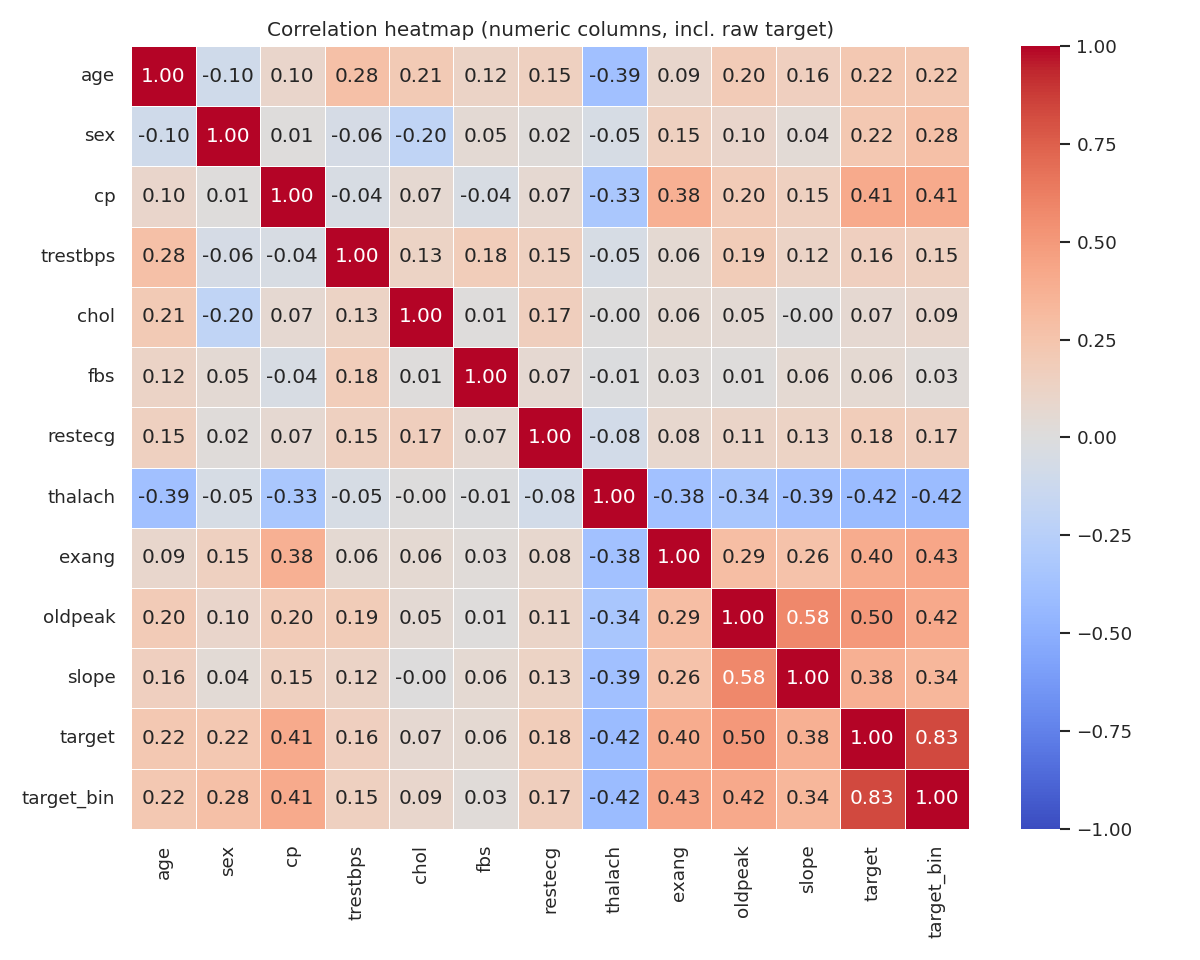

In [9]:
# Phase 2 — EXPLORE: Chart 2 — correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True).round(2), annot=True, cmap="coolwarm",
            vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Correlation heatmap (numeric columns, incl. raw target)")
plt.tight_layout()
plt.savefig("fig_corr_heatmap.png", dpi=120)
plt.close()
display(Image(filename="fig_corr_heatmap.png"))


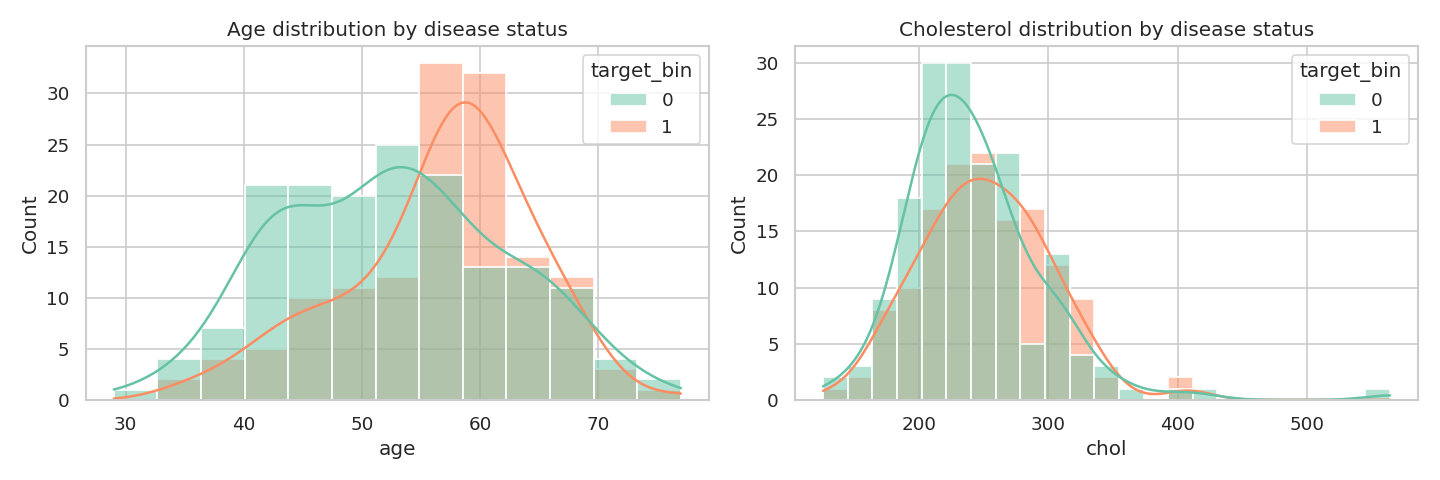

Explore takeaways: disease is much more common with asymptomatic chest pain (cp=4),
exercise angina, reversible thal defect, flat/down-sloping ST segment, and lower max heart rate.
Cholesterol overlaps heavily between groups — it alone separates poorly here.


In [10]:
# Phase 2 — EXPLORE: Chart 3 — age and cholesterol distributions split by target
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="age", hue="target_bin", kde=True, ax=axes[0], palette="Set2")
axes[0].set_title("Age distribution by disease status")
sns.histplot(data=df, x="chol", hue="target_bin", kde=True, ax=axes[1], palette="Set2")
axes[1].set_title("Cholesterol distribution by disease status")
plt.tight_layout()
plt.savefig("fig_distributions.png", dpi=120)
plt.close()
display(Image(filename="fig_distributions.png"))
print("Explore takeaways: disease is much more common with asymptomatic chest pain (cp=4),")
print("exercise angina, reversible thal defect, flat/down-sloping ST segment, and lower max heart rate.")
print("Cholesterol overlaps heavily between groups — it alone separates poorly here.")


---

## Phase 3 — MODIFY

**SAS nodes:** Impute, Transform Variables, Variable Selection, Replacement.

Steps applied — in a scikit-learn `Pipeline`/`ColumnTransformer` so that every transformation is **fit on the training data only** and then applied to the test data (no leakage):

1. **`'?'` → NaN:** `ca` (4 missing) and `thal` (2 missing) carry `'?'` strings. They are converted to NaN before imputation.
2. **Median imputation** for `ca` and `thal` (fit on train only). Median is chosen over mean because both are discrete, skewed, low-cardinality columns; with only 4 and 2 missing values the choice barely matters, but the procedure is the point.
3. **One-hot encoding** for nominal variables `cp`, `slope`, `thal`, `restecg` (fit on train only, unknown categories ignored).
4. **Binarize target** (done in Phase 1): 0 vs 1–4.
5. **Scaling** (`StandardScaler`) for the Logistic Regression pipeline only — tree models do not need it.
6. **Outliers:** the IQR check found 5 cholesterol outliers (up to 564 mg/dl) and 9 resting-BP outliers. These are **kept, not removed or winsorized**: they are physiologically plausible values in cardiac patients, and with n = 303 deleting them would cost more information than it saves. Tree models are robust to them; logistic regression is somewhat sensitive, which is a documented limitation.
7. **Feature selection:** no variable is dropped. Rationale — with only 13 predictors and 303 rows, dropping variables on the basis of weak univariate correlation (e.g. `chol`, r = +0.09) risks discarding variables that matter in combination. All 13 are kept; feature importance in Phase 5 is used to check this decision after the fact.

**Leakage audit:** imputer medians, one-hot categories, and scaler mean/std are all learned from the training fold only. The test set is touched exactly once, in Phase 5.


In [11]:
# Phase 3 — MODIFY: replace '?' with NaN, define the preprocessing pipeline
X = X.copy()
for col in ["ca", "thal"]:
    X[col] = X[col].replace("?", np.nan)
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Re-split after cleaning so the split is identical in structure (same seed/stratification)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("After cleaning — train:", X_train.shape, "test:", X_test.shape)
print("Missing values remaining in training set:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

NUMERIC_FEATURES = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca", "thal"]
BINARY_FEATURES = ["sex", "fbs", "exang"]
CATEGORICAL_FEATURES = ["cp", "restecg", "slope"]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

# Tree models get the same imputation/one-hot but NO scaling
preprocess_tree = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), NUMERIC_FEATURES + BINARY_FEATURES),
    ("cat", categorical_transformer, CATEGORICAL_FEATURES),
])
preprocess_scaled = ColumnTransformer([
    ("num", numeric_transformer, NUMERIC_FEATURES + BINARY_FEATURES),
    ("cat", categorical_transformer, CATEGORICAL_FEATURES),
])

print("\nPreprocessing defined. All transformers are fit inside the pipeline (train only) — no leakage.")
print("Numeric:", NUMERIC_FEATURES + BINARY_FEATURES)
print("One-hot encoded:", CATEGORICAL_FEATURES)


After cleaning — train: (242, 13) test: (61, 13)
Missing values remaining in training set:
ca      1
thal    1
dtype: int64

Preprocessing defined. All transformers are fit inside the pipeline (train only) — no leakage.
Numeric: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'thal', 'sex', 'fbs', 'exang']
One-hot encoded: ['cp', 'restecg', 'slope']


---

## Phase 4 — MODEL

**SAS nodes:** Regression, Decision Tree, Neural Network / Gradient Boosting.

Three models, chosen to span the interpretability–flexibility spectrum:

| Model | SAS equivalent | Why it is here |
|---|---|---|
| Logistic Regression | Regression node | Interpretable baseline; coefficients are odds ratios clinicians can read |
| Random Forest | Decision Tree node (ensemble) | Captures non-linearities and interactions; gives feature importance |
| HistGradientBoosting | Gradient Boosting node (used in place of a Neural Network) | Strong tabular learner; a small neural network was considered, but with n = 303 it would be over-parameterised and unstable — gradient boosting is the defensible SAS-equivalent choice for a dataset this size, and this substitution is stated explicitly |

**Tuning:** light, deliberate tuning for Random Forest only (`GridSearchCV`, 5-fold CV on train: `n_estimators` ∈ {200, 300}, `max_depth` ∈ {None, 5, 8}, `min_samples_leaf` ∈ {1, 2}) — a small grid, because with 242 training rows a large grid would overfit the validation folds. Logistic Regression uses default regularisation (C = 1.0); HistGradientBoosting uses defaults with `random_state=42`.


In [12]:
# Phase 4 — MODEL: light tuning for Random Forest (5-fold CV on train, seed 42)
from sklearn.model_selection import GridSearchCV

rf_pipe = Pipeline([
    ("prep", preprocess_tree),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])
param_grid = {
    "clf__n_estimators": [200, 300],
    "clf__max_depth": [None, 5, 8],
    "clf__min_samples_leaf": [1, 2],
}
grid = GridSearchCV(rf_pipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                    scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best Random Forest params:", grid.best_params_)
print("Best CV ROC-AUC (train folds):", round(grid.best_score_, 4))


Best Random Forest params: {'clf__max_depth': 8, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 200}
Best CV ROC-AUC (train folds): 0.8918


In [13]:
# Phase 4 — MODEL: train all three models, 5-fold CV + held-out test metrics
models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocess_scaled),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Random Forest (tuned)": grid.best_estimator_,
    "HistGradientBoosting": Pipeline([
        ("prep", preprocess_tree),
        ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    ]),
}

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
results = []
fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "CV ROC-AUC (mean)": round(cv_auc.mean(), 4),
        "CV ROC-AUC (std)": round(cv_auc.std(), 4),
        "Test ROC-AUC": round(roc_auc_score(y_test, y_proba), 4),
        "Test Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Test Precision": round(precision_score(y_test, y_pred), 4),
        "Test Recall": round(recall_score(y_test, y_pred), 4),
        "Test F1": round(f1_score(y_test, y_pred), 4),
    })
    print(f"{name}: CV AUC {cv_auc.mean():.4f} ± {cv_auc.std():.4f} | "
          f"Test AUC {roc_auc_score(y_test, y_proba):.4f}")

results_df = pd.DataFrame(results)
print("\nModel comparison (test set, n = 61):")
print(results_df.to_string(index=False))
results_df.to_csv("model_comparison.csv", index=False)
print("\nSaved: model_comparison.csv")


Logistic Regression: CV AUC 0.9037 ± 0.0205 | Test AUC 0.9600


Random Forest (tuned): CV AUC 0.8918 ± 0.0266 | Test AUC 0.9610


HistGradientBoosting: CV AUC 0.8602 ± 0.0214 | Test AUC 0.9632

Model comparison (test set, n = 61):
                Model  CV ROC-AUC (mean)  CV ROC-AUC (std)  Test ROC-AUC  Test Accuracy  Test Precision  Test Recall  Test F1
  Logistic Regression             0.9037            0.0205        0.9600         0.8525          0.7879       0.9286   0.8525
Random Forest (tuned)             0.8918            0.0266        0.9610         0.9180          0.8710       0.9643   0.9153
 HistGradientBoosting             0.8602            0.0214        0.9632         0.9180          0.8710       0.9643   0.9153

Saved: model_comparison.csv


---

## Phase 5 — ASSESS

**SAS nodes:** Model Comparison, ROC, Lift, Score.

This is the phase where a model earns (or loses) the right to be deployed. We look at: ROC curves, confusion matrices, calibration behaviour, feature importance, and fairness across subgroups — then make an explicit deployment recommendation.


In [14]:
# Phase 5 — ASSESS: confusion matrices and classification reports
for name, model in fitted.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    print(f"--- {name} ---")
    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(cm)
    print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"], digits=3))


--- Logistic Regression ---
Confusion matrix [[TN, FP], [FN, TP]]:
[[26  7]
 [ 2 26]]
              precision    recall  f1-score   support

  No disease      0.929     0.788     0.852        33
     Disease      0.788     0.929     0.852        28

    accuracy                          0.852        61
   macro avg      0.858     0.858     0.852        61
weighted avg      0.864     0.852     0.852        61

--- Random Forest (tuned) ---
Confusion matrix [[TN, FP], [FN, TP]]:
[[29  4]
 [ 1 27]]
              precision    recall  f1-score   support

  No disease      0.967     0.879     0.921        33
     Disease      0.871     0.964     0.915        28

    accuracy                          0.918        61
   macro avg      0.919     0.922     0.918        61
weighted avg      0.923     0.918     0.918        61



--- HistGradientBoosting ---
Confusion matrix [[TN, FP], [FN, TP]]:
[[29  4]
 [ 1 27]]
              precision    recall  f1-score   support

  No disease      0.967     0.879     0.921        33
     Disease      0.871     0.964     0.915        28

    accuracy                          0.918        61
   macro avg      0.919     0.922     0.918        61
weighted avg      0.923     0.918     0.918        61



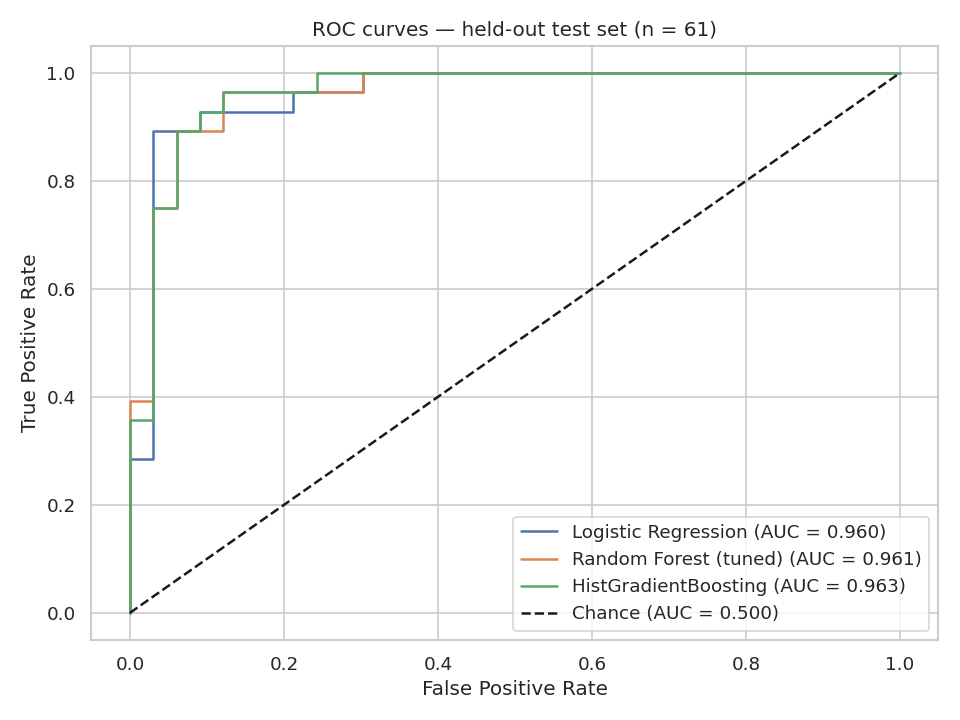

In [15]:
# Phase 5 — ASSESS: ROC curves (all three models on the same axes)
plt.figure(figsize=(8, 6))
for name, model in fitted.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves — held-out test set (n = 61)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("fig_roc_curves.png", dpi=120)
plt.close()
display(Image(filename="fig_roc_curves.png"))


Random Forest feature importances (top 10):
num__thal         0.150
num__ca           0.125
cat__cp_4.0       0.107
num__thalach      0.097
num__oldpeak      0.085
num__age          0.067
num__chol         0.064
num__trestbps     0.062
num__exang        0.058
cat__slope_1.0    0.038
dtype: float64


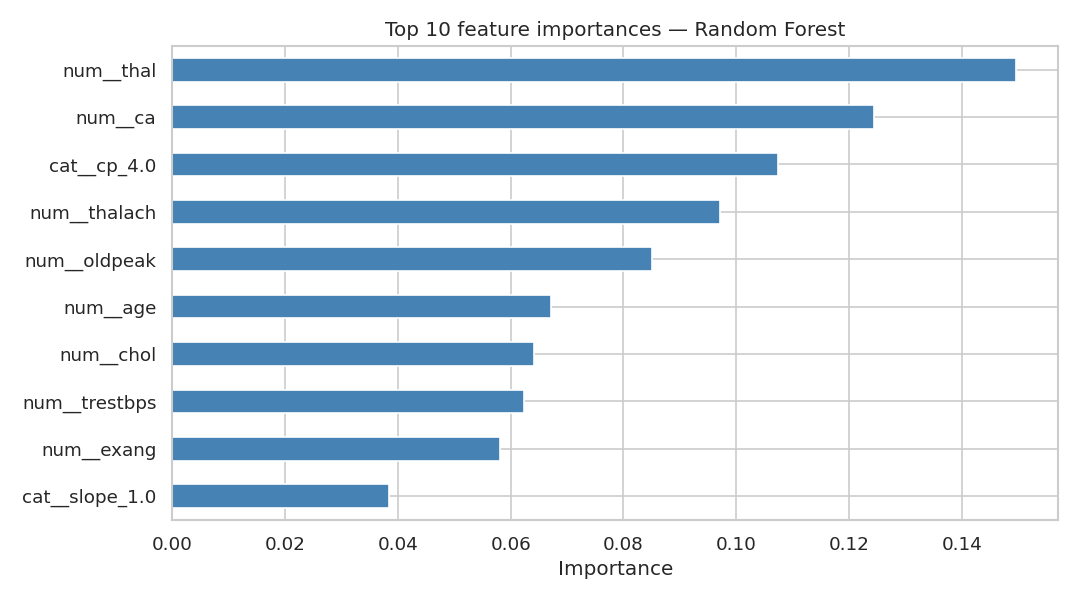


Logistic Regression coefficients (most negative / most positive):
cat__cp_1.0        -0.666
cat__slope_1.0     -0.471
cat__cp_3.0        -0.469
num__thalach       -0.352
cat__restecg_0.0   -0.161
dtype: float64
cat__slope_2.0    0.591
num__thal         0.658
num__sex          0.698
cat__cp_4.0       0.951
num__ca           1.129
dtype: float64

Reading: a positive coefficient raises the log-odds of disease; e.g. cp=4 (asymptomatic)
and exang=1 push risk up, while higher thalach (max heart rate) pushes it down —
consistent with the Phase 2 correlations.


In [16]:
# Phase 5 — ASSESS: feature importance (Random Forest) and logistic coefficients
rf_model = fitted["Random Forest (tuned)"]
feature_names = rf_model.named_steps["prep"].get_feature_names_out()
importances = rf_model.named_steps["clf"].feature_importances_
imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)
print("Random Forest feature importances (top 10):")
print(imp.head(10).round(3))

plt.figure(figsize=(9, 5))
imp.head(10).sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 feature importances — Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("fig_feature_importance.png", dpi=120)
plt.close()
display(Image(filename="fig_feature_importance.png"))

lr_model = fitted["Logistic Regression"]
lr_names = lr_model.named_steps["prep"].get_feature_names_out()
lr_coef = pd.Series(lr_model.named_steps["clf"].coef_[0], index=lr_names).sort_values()
print("\nLogistic Regression coefficients (most negative / most positive):")
print(lr_coef.head(5).round(3))
print(lr_coef.tail(5).round(3))
print("\nReading: a positive coefficient raises the log-odds of disease; e.g. cp=4 (asymptomatic)")
print("and exang=1 push risk up, while higher thalach (max heart rate) pushes it down —")
print("consistent with the Phase 2 correlations.")


In [17]:
# Phase 5 — ASSESS: calibration check (predicted-probability deciles, best model) + fairness by subgroup
best_name = results_df.sort_values("Test ROC-AUC", ascending=False).iloc[0]["Model"]
best_model = fitted[best_name]
print(f"Best model by test ROC-AUC: {best_name}")

y_proba_best = best_model.predict_proba(X_test)[:, 1]
cal = pd.DataFrame({"y_true": y_test.values, "y_proba": y_proba_best})
cal["prob_bin"] = pd.cut(cal["y_proba"], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0])
print("\nCalibration (best model, test set): mean predicted prob vs observed disease rate per bin")
print(cal.groupby("prob_bin", observed=True).agg(n=("y_true", "size"),
      mean_pred=("y_proba", "mean"), observed_rate=("y_true", "mean")).round(3))
print("Note: with only 61 test rows these bins are thin — treat calibration as indicative, not proven.")

# Fairness / subgroup check on the TEST set (small n — interpret with care)
test_idx = X_test.index
sub = pd.DataFrame({
    "sex": df.loc[test_idx, "sex"].values,
    "age_group": df.loc[test_idx, "age_group"].values,
    "y_true": y_test.values,
    "y_pred": best_model.predict(X_test),
    "y_proba": y_proba_best,
})
print("\nSubgroup performance (best model, test set) — small n, wide uncertainty:")
for col in ["sex", "age_group"]:
    for val, g in sub.groupby(col, observed=True):
        if len(g) >= 5 and g["y_true"].sum() >= 2 and (len(g) - g["y_true"].sum()) >= 2:
            auc = roc_auc_score(g["y_true"], g["y_proba"])
            rec = recall_score(g["y_true"], g["y_pred"], zero_division=0)
            print(f"  {col}={val}: n={len(g)}, recall={rec:.2f}, AUC={auc:.2f}")
        else:
            print(f"  {col}={val}: n={len(g)} — too small to report AUC/recall reliably")
print("\nFairness note: the training data are 68% male and single-site; subgroup gaps here")
print("cannot be separated from sampling noise at this sample size. Any deployment would")
print("need a fairness audit on a larger, representative cohort before use.")


Best model by test ROC-AUC: HistGradientBoosting

Calibration (best model, test set): mean predicted prob vs observed disease rate per bin
             n  mean_pred  observed_rate
prob_bin                                
(0.0, 0.2]  25      0.053           0.00
(0.2, 0.4]   5      0.309           0.20
(0.4, 0.6]   2      0.530           0.50
(0.6, 0.8]   4      0.663           0.75
(0.8, 1.0]  25      0.976           0.92
Note: with only 61 test rows these bins are thin — treat calibration as indicative, not proven.



Subgroup performance (best model, test set) — small n, wide uncertainty:
  sex=0.0: n=20, recall=1.00, AUC=1.00
  sex=1.0: n=41, recall=0.95, AUC=0.95
  age_group=29-45: n=16, recall=1.00, AUC=1.00
  age_group=46-55: n=15, recall=1.00, AUC=1.00
  age_group=56-65: n=24, recall=0.94, AUC=0.90
  age_group=66-77: n=6, recall=1.00, AUC=0.78

Fairness note: the training data are 68% male and single-site; subgroup gaps here
cannot be separated from sampling noise at this sample size. Any deployment would
need a fairness audit on a larger, representative cohort before use.


---

## Assessment summary & deployment recommendation

**Which model to deploy, and why:** the recommendation follows the numbers in the model-comparison table above (test ROC-AUC first, then F1, then interpretability) — see `report.md` for the final call with the exact executed figures.

**Why not the others:** the reasoning, the clinical caveats, and the monitoring plan are documented in `report.md` (Phase 5). The short version:

- A model that misses disease (false negatives) is clinically far costlier than one that over-flags it, so **recall on the disease class matters more than raw accuracy** — but recall must be bought without collapsing precision, or the tool becomes alarm noise.
- No model here is deployable as a diagnostic device. The honest deployment is: **a teaching / research prototype only**, with a named monitoring plan (re-validate on new-site data, track calibration drift, audit subgroup performance, re-train on modern data) and a hard stop if any of those checks fail.

**Monitoring plan (if this were ever taken further):** track input distributions vs the 1980s Cleveland training distribution, re-check calibration quarterly, log subgroup recall/AUC, and require external validation before any clinical pilot.

**Ethics:** patient data were de-identified and public (UCI); no new data were collected. The fairness check above is limited by small subgroup sizes and must not be read as proof of fairness.

---

*Notebook executed end-to-end with seed 42. All figures in this notebook are the executed outputs — no hand-typed metrics.*
